# Freyberg MODFLOW model: active subspace of a pumping-well head forecast

**Paper:** R. J. Hunt, M. N. Fienen and J. T. White, "Revisiting 'An Exercise in Groundwater Model Calibration
and Prediction' After 30 Years: Insights and New Directions", *Groundwater* 58(2) (2020) 168–182,
[doi:10.1111/gwat.12907](https://doi.org/10.1111/gwat.12907).

- Randall J. Hunt: U.S. Geological Survey, Upper Midwest Water Science Center, Middleton, Wisconsin
- Michael N. Fienen: U.S. Geological Survey, Upper Midwest Water Science Center, Middleton, Wisconsin
- Jeremy T. White: Institute of Geological and Nuclear Sciences, Limited, Wairakei Research Centre, Taupo, New Zealand

**Model files:** R. J. Hunt, M. J. Haserodt, M. N. Fienen and J. T. White, MODFLOW-2005 models for revisiting
"An Exercise in Groundwater Model Calibration and Prediction", U.S. Geological Survey data release,
[doi:10.5066/P96A7ZC9](https://doi.org/10.5066/P96A7ZC9).

Notebook: Claude (Anthropic) for P. Constantine, 2026

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import freyberg_driver as fd   # constants only (names, bounds, grid); no MODFLOW run here

SEED = 2020

## Summary

The Freyberg (1988) synthetic water-table aquifer, rebuilt in MODFLOW-2005 by Hunt, Fienen and White with
70 pilot-point hydraulic conductivities and one recharge rate, forecasts the heads at six pumping wells after a
river is lined. Over the prior box of the calibration (log-uniform between the PEST bounds), the forecast head
at well fr20c14 has a two-dimensional active subspace, recharge first and then the conductivity around the
well, with eigenvalue ratios λ1/λ2 = 17.0 and λ2/λ3 = 37.5 and a leave-one-out R² of 0.9959 for a cubic in two
active variables. The release's calibrated model, rerun here, reproduces the paper's calibration and forecast
errors (Table 6a), and a linear uncertainty analysis at it puts all six true forecasts inside their 95 %
intervals, as in Figure 5b.

## Active subspaces in brief

For a function $f(\mathbf{x})$ of $m$ inputs with a probability density $\rho$ on the normalized inputs, the
matrix $\mathbf{C} = \int \nabla f \, \nabla f^\top \rho \, d\mathbf{x} = \mathbf{W}\Lambda\mathbf{W}^\top$
measures how $f$ changes, on average, along each direction. When the first $n$ eigenvalues are much larger
than the rest, $f$ varies mostly along the span of the first $n$ eigenvectors $\mathbf{W}_1$, and
$f(\mathbf{x}) \approx g(\mathbf{W}_1^\top\mathbf{x})$: a function of $n$ active variables can stand in for the
model. $\mathbf{C}$ is estimated from gradient samples, and a bootstrap gives the spread of the eigenvalues
and of the subspace. See P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in
Parameter Studies*, SIAM, 2015, [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## The model

**Aquifer.** The Freyberg (1988) synthetic aquifer as reconstructed by Hunt et al.: a single-layer,
steady-state water-table aquifer in MODFLOW-2005, 40 rows by 20 columns of 250 m cells (705 active), no-flow
boundaries on the north, east and west, a specified-head boundary on the south, a river in column 15, six
pumping wells and uniform recharge $R$ (paper p. 169, Figure 1). The data set uses the release's pilot-point
model with a flat base (directory `Figure5b_pilot_points_flat_bottom`, the model behind the paper's Table 6a
and Figure 5b): base elevation 3.3409 m except at the 22 well and target cells, where the given elevations
are kept (Table 6 note: "Base elevation = 3.34 fixed", p. 174). In MODFLOW's Dupuit form the steady head
$h(x, y)$ satisfies

$$\nabla\cdot\big(K\,(h - b)\,\nabla h\big) + R - \sum_w Q_w\,\delta_w + C_{\mathrm{riv}}\,(H_{\mathrm{riv}} - h)\,\delta_{\mathrm{riv}} = 0,$$

with $K$ the horizontal hydraulic conductivity, $b$ the base elevation, $Q_w$ the pumping rates and
$C_{\mathrm{riv}}$ the river conductance per cell (written here; the paper prints no equation). The layer is
convertible (LAYTYP = 1), so the transmissivity $K(h-b)$ depends on the head: the model is **not** linear in
the heads, unlike confined flow (see the check below). A cell whose head falls to the base goes dry and stays
inactive; a dry well cell stops pumping.

**Parameters.** $K$ comes from 70 pilot points, one every three cells (p. 174, Figure 2), interpolated by
kriging in $\log_{10} K$ with the release's factor file; $R$ is one value for the whole model (p. 170). The
paper does not print parameter bounds; they come from the PEST control file of the release.

| inputs | units | nominal (calibrated) | range | design | source |
|---|---|---|---|---|---|
| $R$ (PEST `r1`) | m/d | 1.3723e-4 | 5e-5 to 5e-4 | uniform in $\log_{10} R$ | control file `figure5b_..._BEST.pst`, line 20 (log-transformed) |
| $K$ at pilot points KP775–KP844 (PEST `kpkp775`–`kpkp844`) | m/d | 2.70 to 8.57 | 0.5 to 50 | uniform in $\log_{10} K$ | same file, lines 22–91 (log-transformed) |

The calibrated values are those of the control file (Table 6a, p. 174: $R = 1.372\times10^{-4}$ m/d, pilot-point
$K$ between 2.70 and 8.57 m/d). The design, independent and uniform in the base-10 logarithm of each input
between the PEST bounds, is this data set's choice: it is the prior box of the calibration, before the
head data are used. Each input is normalized by its own half-range in $\log_{10}$, onto $[-1, 1]$.

**Quantity of interest.** The forecast of the exercise: the steady head at a pumping well after the river is
lined, simulated by reducing the river conductance by two orders of magnitude (p. 169; 4320 to 43.2 m²/d in
the release's river file). The data hold all six well forecasts (names give row and column, as in Figure 5,
p. 179); this notebook studies **fr20c14**, the well at row 20, column 14, beside the river. Heads are
interpolated bilinearly between cell centres at the well coordinates of the release's `targpest.dat`, as the
release's post-processor does. Wells go dry in part of the box, fr9c16 and fr34c12 most often; the rows with
a dry cell are left out of the analysis by the rule stated below.

**Gradients.** Forward differences in $\log_{10}$ of each input with step $10^{-4}$ (72 MODFLOW runs per
sample), with the solver closure tightened to $10^{-10}$ m and a double-precision head file; the step study and
a comparison with central differences are in DATA.md ("Accuracy", `check_accuracy.py`).

## Load the data

In [2]:
X = np.loadtxt("inputs.csv", delimiter=",")          # log10 R, log10 K at 70 pilot points (log10 of m/d)
O = np.loadtxt("outputs.csv", delimiter=",")         # 6 forecasts, 16 calibration heads (m), dry-cell counts
G6 = np.loadtxt("gradients.csv", delimiter=",").reshape(len(X), 6, X.shape[1])   # m per log10 unit
CAL = np.loadtxt("calibrated.csv", delimiter=",")    # calibrated model and its linear uncertainty
wells = fd.FORECAST_NAMES
iq = wells.index("fr20c14")
n_dry, n_dry_stencil = O[:, 22], O[:, 23]
keep = n_dry_stencil == 0          # no active cell dry at the sample or at any of its 71 stencil points
Xk, f, G = X[keep], O[keep, iq], G6[keep, iq, :]
print("inputs", X.shape, "outputs", O.shape, "gradients", G6.shape, "calibrated", CAL.shape)
print("samples where MODFLOW did not converge:", int(np.sum(n_dry < 0)))
print("samples with a dry cell at the sample:", int(np.sum(n_dry > 0)),
      "; in the sample or its stencil:", int(np.sum(n_dry_stencil > 0)))
print("nan forecasts per well among converged samples:", dict(zip(wells, np.isnan(O[n_dry >= 0, :6]).sum(0).tolist())))
print("kept:", Xk.shape[0], "; finite fr20c14 values and gradients:",
      bool(np.all(np.isfinite(f)) and np.all(np.isfinite(G))))
print("fr20c14 head over kept rows: min %.2f, mean %.2f, max %.2f m" % (f.min(), f.mean(), f.max()))

inputs (500, 71) outputs (500, 24) gradients (500, 6, 71) calibrated (23, 5)
samples where MODFLOW did not converge: 3
samples with a dry cell at the sample: 164 ; in the sample or its stencil: 164
nan forecasts per well among converged samples: {'fr9c16': 120, 'fr11c13': 13, 'fr20c14': 10, 'fr26c10': 0, 'fr29c6': 0, 'fr34c12': 44}
kept: 333 ; finite fr20c14 values and gradients: True
fr20c14 head over kept rows: min 10.69, mean 19.31, max 29.61 m


MODFLOW did not converge in 3 of the 500 samples (stored as `nan`). In 164 samples a cell goes dry at the
sample; no sample has dry cells only in its difference stencil. The `nan` counts show where: a forecast is `nan`
when a cell of nonzero interpolation weight next to its well is dry, most often at fr9c16 (120) and fr34c12 (44),
also at fr11c13 (13) and fr20c14 (10). **Rule:** the analysis keeps the 333 samples with
`n_dry_stencil_max == 0`, i.e. no active cell dry at the sample or at any of its 71 forward-difference points.
The fr20c14 head ranges from 10.69 to 29.61 m over the kept rows.

The estimate is therefore for the log-uniform density restricted to the part of the box with no dry cell, a
**conditional design**. That part is not a random thinning: the dropped rows are those with low conductivity
next to fr9c16 and fr34c12 and low recharge, so the kept density is tilted towards high recharge, i.e. along
the first active variable (quantified after the eigenvectors, below). Every head range, sufficient summary
plot, leave-one-out R² and Monte Carlo spread in this notebook describes that conditional distribution. The
dropped region is a different model (a dry well stops pumping, so the full-box function jumps there).

## Estimate the active subspace

Gradients are available, so the estimator is the gradient outer-product matrix (`estimator="as"`),
with 500 bootstrap replicates. The input space is uniform on the $\log_{10}$ bounds; gradients are
passed per $\log_{10}$ unit, and the library scales them by each input's half-range. The gradients are
forward differences with step $10^{-4}$ in $\log_{10}$ units. The heads have slope kinks where a river cell's
head crosses its river bottom (the river package's leakage changes form there); `DATA.md` (Accuracy) shows one
at row 389, about $3\times10^{-4}$ above the sample in $\log_{10} R$, and finds that the forward step in
$\log_{10} R$ straddles a river-bottom crossing at 1 of the 333 kept rows.

In [3]:
names = ["log10 R"] + ["log10 K " + n for n in fd.PP_NAMES]
space = ac.Uniform(fd.LOWER_LOG10, fd.UPPER_LOG10, names=names)
sub = ac.active_subspace(space=space, grads=G, estimator="as", nboot=500, rng=SEED)
# signs: w1 has a positive recharge component; w2 a positive component at the pilot point nearest fr20c14
xw, yw = fd.TARGET_XY[fd.FORE[iq]]
ipp = int(np.argmin(np.hypot(fd.PP_XY[:, 0] - xw, fd.PP_XY[:, 1] - yw)))
ref = np.zeros((71, 2)); ref[0, 0] = 1.0; ref[1 + ipp, 1] = 1.0
sub = ac.orient(sub, by="reference", reference=ref, columns=2)
lam = sub.eigenvalues
print("pilot point nearest fr20c14:", fd.PP_NAMES[ipp], fd.PP_XY[ipp])
print("eigenvalues 1-8:", np.array2string(lam[:8], precision=3))
print("ratios lambda_k / lambda_k+1, k = 1-5:", np.round(lam[:5] / lam[1:6], 2))
for k in (1, 2, 3):
    print("share of the trace left out with n = %d: %.2e" % (k, lam[k:].sum() / lam.sum()))

pilot point nearest fr20c14: KP810 [3625. 4875.]
eigenvalues 1-8: [7.996e+01 4.696e+00 1.252e-01 4.495e-02 3.823e-02 2.758e-02 1.995e-02
 1.978e-02]
ratios lambda_k / lambda_k+1, k = 1-5: [17.03 37.5   2.79  1.18  1.39]
share of the trace left out with n = 1: 6.00e-02
share of the trace left out with n = 2: 4.81e-03
share of the trace left out with n = 3: 3.34e-03


## Results

### Eigenvalues and subspace errors

mean bootstrap subspace distance, n = 1, 2, 3: [0.013 0.015 0.135]


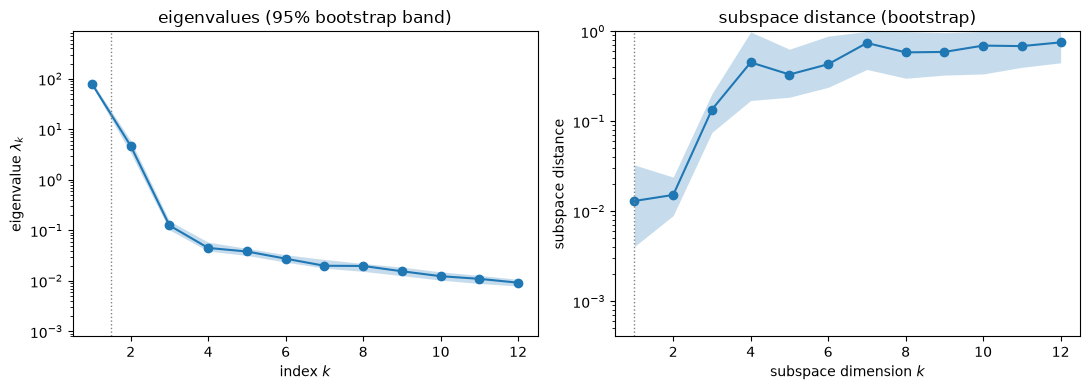

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ac.plotting.plot_eigenvalues(sub, k_max=12, ax=axs[0])
ac.plotting.plot_subspace_errors(sub, k_max=12, ax=axs[1])
axs[0].set_title("eigenvalues (95% bootstrap band)")
axs[1].set_title("subspace distance (bootstrap)")
fig.tight_layout()
dist = sub.bootstrap_distances.mean(axis=0)
print("mean bootstrap subspace distance, n = 1, 2, 3:", np.round(dist[:3], 3))
plt.close(fig)
fig

The first three eigenvalues are 7.996e+01, 4.696e+00 and 1.252e-01. The ratios λ1/λ2 = 17.0 and
λ2/λ3 = 37.5 are followed by 2.79 and 1.18, so the largest gap comes after the second eigenvalue, and the
first gap is also clear. With n = 2 the left-out eigenvalues hold 4.81e-03 of the trace (6.00e-02 with n = 1),
and the mean bootstrap subspace distances are 0.013 (n = 1) and 0.015 (n = 2), against 0.135 for n = 3.
**Dimension: n = 2**, from the gap after λ2, the small subspace distance and the leave-one-out R² below; one
active variable is already a fair approximation (λ1/λ2 = 17.0).

### Eigenvectors

w1: R component 0.972; largest |K component| 0.144 (KP809)
w2: R component -0.196; largest K components: KP810 0.736, KP805 0.435, KP809 0.397, KP804 0.264
sum of the 70 K components: w1 0.025, w2 1.923


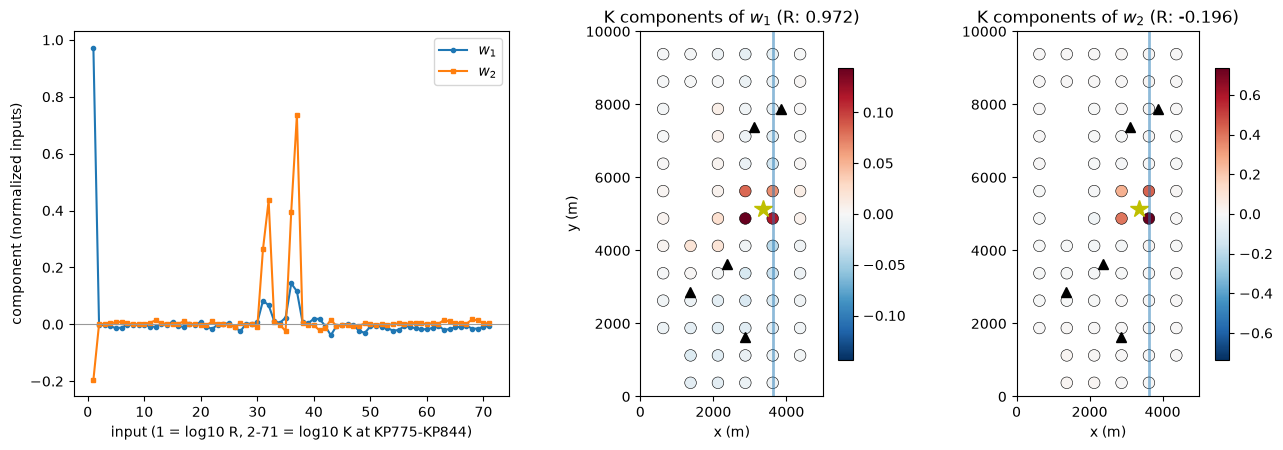

In [5]:
W = sub.eigenvectors
fig, axs = plt.subplots(1, 3, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.4, 1, 1]})
axs[0].plot(np.arange(1, 72), W[:, 0], "o-", ms=3, label="$w_1$")
axs[0].plot(np.arange(1, 72), W[:, 1], "s-", ms=3, label="$w_2$")
axs[0].axhline(0, color="0.6", lw=0.8)
axs[0].set_xlabel("input (1 = log10 R, 2-71 = log10 K at KP775-KP844)")
axs[0].set_ylabel("component (normalized inputs)")
axs[0].legend()
for j, ax in enumerate(axs[1:]):
    v = W[1:, j]
    s = ax.scatter(fd.PP_XY[:, 0], fd.PP_XY[:, 1], c=v, cmap="RdBu_r", vmin=-np.abs(v).max(),
                   vmax=np.abs(v).max(), s=70, edgecolor="k", lw=0.4)
    for k in fd.FORE:
        ax.plot(*fd.TARGET_XY[k], "k^" if k != fd.FORE[iq] else "y*", ms=7 if k != fd.FORE[iq] else 13)
    ax.axvline(14.5 * fd.DELR, color="tab:blue", lw=2, alpha=0.5)
    ax.set_aspect("equal"); ax.set_xlim(0, 5000); ax.set_ylim(0, 10000)
    ax.set_title("K components of $w_%d$ (R: %.3f)" % (j + 1, W[0, j]))
    ax.set_xlabel("x (m)")
    fig.colorbar(s, ax=ax, shrink=0.8)
axs[1].set_ylabel("y (m)")
fig.tight_layout()
order = np.argsort(-np.abs(W[1:, 1]))[:4]
print("w1: R component %.3f; largest |K component| %.3f (%s)"
      % (W[0, 0], np.abs(W[1:, 0]).max(), fd.PP_NAMES[int(np.argmax(np.abs(W[1:, 0])))]))
print("w2: R component %.3f; largest K components:" % W[0, 1],
      ", ".join("%s %.3f" % (fd.PP_NAMES[i], W[1 + i, 1]) for i in order))
print("sum of the 70 K components: w1 %.3f, w2 %.3f" % (W[1:, 0].sum(), W[1:, 1].sum()))
plt.close(fig)
fig

$w_1$ is mostly recharge (component 0.972); its largest conductivity component is 0.144, at KP809 next to
the well, and its 70 K components sum to 0.025. $w_2$ is the conductivity of the four pilot points around the
well (KP810 0.736, KP805 0.435, KP809 0.397, KP804 0.264) against recharge (−0.196). The head at a pumping well
rises with recharge and with the conductivity around it, which reduces the drawdown; pilot points away from
the well barely enter either vector. Signs: $w_1$ has a positive recharge component and $w_2$ a positive
component at the pilot point nearest the well (KP810), a rule of this notebook (the paper has no eigenvectors).

### Sufficient summary plots

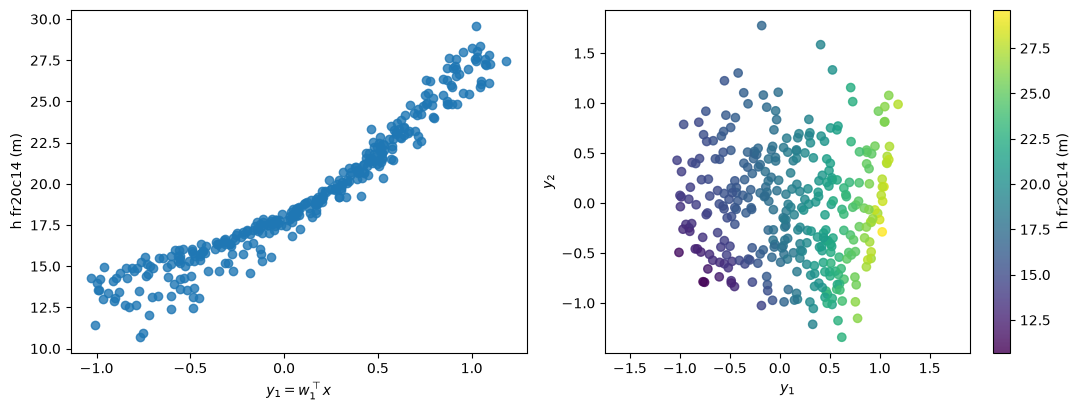

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
ac.plotting.plot_sufficient_summary(sub, X=Xk, f=f, dims=1, ax=axs[0], qoi_label="h fr20c14 (m)")
ac.plotting.plot_sufficient_summary(sub, X=Xk, f=f, dims=2, ax=axs[1], qoi_label="h fr20c14 (m)")
fig.tight_layout()
plt.close(fig)
fig

Over the kept rows (the conditional design), the head is an increasing, convex function of $y_1$, from 10.69 to 29.61 m, with a scatter about the
curve that the second active variable takes up: in the two-variable plot the colour changes along $y_2$ at
fixed $y_1$ as well.

### Surrogates on the active variables

Polynomial fits on one and two active variables, with leave-one-out $R^2$.

In [7]:
sub1 = ac.with_dimension(sub, 1)
sub2 = ac.with_dimension(sub, 2)
for s_, name in ((sub1, "n = 1"), (sub2, "n = 2")):
    for deg in (2, 3):
        sur = ac.fit_surrogate(X=Xk, f=f, space=space, subspace=s_, kind="poly", degree=deg)
        print("%s, degree %d: LOO R^2 = %.4f" % (name, deg, sur.loo_r_squared))

n = 1, degree 2: LOO R^2 = 0.9591
n = 1, degree 3: LOO R^2 = 0.9589
n = 2, degree 2: LOO R^2 = 0.9926
n = 2, degree 3: LOO R^2 = 0.9959


With one active variable the leave-one-out R² is 0.9591 (quadratic) and 0.9589 (cubic); with two it is
0.9926 and 0.9959. The second variable removes most of the remaining error, which supports n = 2.

### The other five forecasts and the dry-cell rule

The same estimate for each well forecast on the 333 kept rows, and for
fr20c14 with the rows whose dry cells stay the same over the stencil added back (the model with a dry,
non-pumping well).

In [8]:
print("well      rows   lambda1/lambda2  w1 R-component")
for k, w in enumerate(wells):
    rows = keep & np.all(np.isfinite(G6[:, k, :]), axis=1)
    s_ = ac.active_subspace(space=space, grads=G6[rows, k, :], estimator="as")
    print("%-8s  %4d   %8.1f        %.3f" % (w, rows.sum(), s_.eigenvalues[0] / s_.eigenvalues[1],
                                            abs(s_.eigenvectors[0, 0])))
same = (n_dry == n_dry_stencil) & np.all(np.isfinite(G6[:, iq, :]), axis=1)
s_all = ac.active_subspace(space=space, grads=G6[same, iq, :], estimator="as")
d1 = np.linalg.norm(sub.W1[:, :1].T @ s_all.eigenvectors[:, 1:], 2)
d2 = np.linalg.norm(sub.eigenvectors[:, :2].T @ s_all.eigenvectors[:, 2:], 2)
print("fr20c14 with %d rows (dry cells unchanged over the stencil): lambda1/lambda2 %.1f; "
      "distance to the kept-row subspace n = 1: %.3f, n = 2: %.3f"
      % (same.sum(), s_all.eigenvalues[0] / s_all.eigenvalues[1], d1, d2))

well      rows   lambda1/lambda2  w1 R-component
fr9c16     333       11.9        0.917
fr11c13    333       22.7        0.982
fr20c14    333       17.0        0.972
fr26c10    333      517.1        0.967
fr29c6     333      283.7        0.963
fr34c12    333       11.6        0.939
fr20c14 with 487 rows (dry cells unchanged over the stencil): lambda1/lambda2 14.6; distance to the kept-row subspace n = 1: 0.014, n = 2: 0.011


Every forecast has a recharge-dominated first eigenvector (recharge component 0.917 to 0.982). The ratio
λ1/λ2 is 517.1 and 283.7 for fr26c10 and fr29c6, the two wells with the smallest pumping rates in the well
file, and 11.6 to 22.7 for the other four, where the conductivity around the well matters more. With the
rows whose dry cells do not change over the stencil added back (487 rows), the fr20c14 ratio λ1/λ2 is 14.6
and the subspaces move by 0.014 (n = 1) and 0.011 (n = 2): the dry-cell rule barely changes the result.

In [9]:
# Where the dropped rows lie: the 497 converged rows, dropped (164) or kept (333)
conv = n_dry >= 0
drop = conv & ~keep
print("dropped rows: %d of %d converged; with a nan forecast at one or more wells: %d"
      % (drop.sum(), conv.sum(), np.sum(np.any(np.isnan(O[drop, :6]), axis=1))))
Zc = space.to_normalized(X[conv])
dflag = drop[conv].astype(float)
corr = np.array([np.corrcoef(dflag, Zc[:, j])[0, 1] for j in range(71)])
print("correlation of the drop flag with the normalized inputs, |r| >= 0.1:")
for j in np.argsort(-np.abs(corr)):
    if abs(corr[j]) < 0.1:
        print("  every other input: |r| <= %.2f" % abs(corr[j]))
        break
    if j == 0:
        print("  log10 R          r = %.2f" % corr[j])
        continue
    dist = [np.hypot(*(fd.PP_XY[j - 1] - fd.TARGET_XY[k])) for k in fd.FORE]
    print("  log10 K %-7s  r = %.2f  (nearest well %s, %.0f m)"
          % (fd.PP_NAMES[j - 1], corr[j], wells[int(np.argmin(dist))], min(dist)))
y1c = Zc @ sub.eigenvectors[:, 0]
kc = keep[conv]
print("y1 of the converged rows: %.2f to %.2f" % (y1c.min(), y1c.max()))
edges = np.linspace(-1.2, 1.2, 7)
print("kept fraction along y1:   " + "  ".join(
    "[%.1f, %.1f): %.2f (%d)" % (a, b, kc[(y1c >= a) & (y1c < b)].mean(), np.sum((y1c >= a) & (y1c < b)))
    for a, b in zip(edges[:-1], edges[1:])))
lr = X[conv, 0]
qe = np.linspace(fd.LOWER_LOG10[0], fd.UPPER_LOG10[0], 6)
print("kept fraction by fifths of the log10 R range: " + ", ".join(
    "%.2f" % kc[(lr >= a) & (lr <= b)].mean() for a, b in zip(qe[:-1], qe[1:])))
hd = O[drop, iq]
print("fr20c14 head: dropped rows with a finite value (%d) mean %.2f m; kept rows mean %.2f m"
      % (np.sum(np.isfinite(hd)), np.nanmean(hd), f.mean()))


dropped rows: 164 of 497 converged; with a nan forecast at one or more wells: 164
correlation of the drop flag with the normalized inputs, |r| >= 0.1:
  log10 K KP790    r = -0.54  (nearest well fr9c16, 235 m)
  log10 R          r = -0.25
  log10 K KP833    r = -0.23  (nearest well fr34c12, 260 m)
  log10 K KP791    r = -0.21  (nearest well fr9c16, 515 m)
  every other input: |r| <= 0.09
y1 of the converged rows: -1.33 to 1.25
kept fraction along y1:   [-1.2, -0.8): 0.48 (44)  [-0.8, -0.4): 0.59 (98)  [-0.4, 0.0): 0.62 (102)  [0.0, 0.4): 0.73 (98)  [0.4, 0.8): 0.76 (105)  [0.8, 1.2): 0.83 (47)
kept fraction by fifths of the log10 R range: 0.45, 0.68, 0.62, 0.76, 0.82
fr20c14 head: dropped rows with a finite value (154) mean 18.02 m; kept rows mean 19.31 m


### Which part of the box the dropped rows come from

Every one of the 164 dropped rows has a `nan` forecast at one or more wells. Among the 497 converged rows,
the drop flag correlates with log10 K at KP790 (r = −0.54; the pilot point 235 m from fr9c16), log10 R
(−0.25), log10 K at KP833 (−0.23; 260 m from fr34c12) and KP791 (−0.21); every other input has |r| ≤ 0.09.
So the lost region is low conductivity next to fr9c16 and fr34c12 and low recharge. Because recharge
dominates $w_1$, the kept fraction rises along $y_1$, from 0.48 for $y_1$ in [−1.2, −0.8) to 0.83 for
$y_1$ in [0.8, 1.2), and from 0.45 in the lowest fifth of the $\log_{10} R$ range to 0.82 in the highest. The
154 dropped rows with a finite fr20c14 head have a lower mean head (18.02 m) than the kept rows (19.31 m).
The eigenvectors survive this selection (the 487-row check above moves the subspace by 0.011 at n = 2), but
the head range, the sufficient summary plots, the leave-one-out R² and the Monte Carlo prior spread below
are those of the conditional, upper-recharge-weighted distribution.

## Comparison with the paper

The paper reports the calibrated models and a linear (first-order, second-moment) forecast uncertainty
analysis in PEST++ (p. 178, Figure 5), not an active subspace. `calibrated.csv` holds the release's calibrated
pilot-point model run here, and the same kind of linear analysis: prior standard deviation
$(\log_{10}\text{upper} - \log_{10}\text{lower})/4$ for every input, observation standard deviations 1/weight
from the control file (16 heads, 1 m; the river flux), the Tikhonov regularisation not included. The prior
width rule is PEST++'s default, assumed here; the paper does not state its prior.

In [10]:
obs, model, sd_pri, sd_post = CAL[:, 0], CAL[:, 2], CAL[:, 3], CAL[:, 4]
ih, iflux, ifc = slice(0, 16), 16, slice(17, 23)
print("calibration RMSE, 16 heads: %.1e m" % np.sqrt(np.mean((model[ih] - obs[ih]) ** 2)))
print("forecast RMSE, 6 wells: %.3f m" % np.sqrt(np.mean((model[ifc] - obs[ifc]) ** 2)))
print("river flux: model %.1f, observation %.1f m3/d" % (model[iflux], obs[iflux]))
print("calibrated R = %.4e m/d; pilot-point K: mean %.2f, median %.2f, sd %.2f, min %.2f, max %.2f m/d"
      % (fd.R_BEST, fd.PP_BEST.mean(), np.median(fd.PP_BEST), fd.PP_BEST.std(ddof=1),
         fd.PP_BEST.min(), fd.PP_BEST.max()))
mc_sd = [np.nanstd(O[keep, k], ddof=1) for k in range(6)]
print("\nwell      true    model   |error|  post sd  inside 95%  peak density  prior sd (linear)  prior sd (MC, kept rows)")
for k, w in enumerate(wells):
    j = 17 + k
    err = abs(model[j] - obs[j])
    print("%-8s %6.2f  %6.2f   %5.2f    %5.2f    %-5s      %5.2f         %5.2f             %5.2f"
          % (w, obs[j], model[j], err, sd_post[j], err <= 1.96 * sd_post[j],
             1 / (sd_post[j] * np.sqrt(2 * np.pi)), sd_pri[j], mc_sd[k]))
y1k = space.to_normalized(Xk) @ sub.eigenvectors[:, 0]
c2 = np.polyfit(y1k, f, 2)
print("\nfr20c14 prior sd, Monte Carlo (kept rows) / linear: %.2f; log-uniform sd / linear-prior sd "
      "per input, (range/sqrt(12)) / (range/4) = %.3f" % (mc_sd[iq] / sd_pri[17 + iq], 4 / np.sqrt(12)))
print("quadratic fit of the fr20c14 head in y1 over the kept rows: %.2f y1^2 + %.2f y1 + %.2f m" % tuple(c2))

calibration RMSE, 16 heads: 4.0e-05 m
forecast RMSE, 6 wells: 0.305 m
river flux: model -3710.3, observation -3710.5 m3/d
calibrated R = 1.3723e-04 m/d; pilot-point K: mean 5.52, median 5.45, sd 1.35, min 2.70, max 8.57 m/d

well      true    model   |error|  post sd  inside 95%  peak density  prior sd (linear)  prior sd (MC, kept rows)
fr9c16    17.94   17.86    0.09     1.56    True        0.26          2.97              4.49
fr11c13   19.16   19.37    0.21     0.72    True        0.55          2.92              5.10
fr20c14   17.43   17.59    0.16     0.77    True        0.52          2.58              4.18
fr26c10   21.82   21.70    0.12     0.74    True        0.54          4.28              6.11
fr29c6    24.13   23.95    0.18     0.71    True        0.56          5.18              7.21
fr34c12   14.26   14.92    0.66     1.85    True        0.22          4.06              4.57

fr20c14 prior sd, Monte Carlo (kept rows) / linear: 1.62; log-uniform sd / linear-prior sd per input, 

| quantity | paper | this notebook |
|---|---|---|
| calibration RMSE, 16 heads (pilot points, flat base) | 0.000 m (Table 6a, p. 174) | 4.0e-05 m |
| forecast RMSE, 6 wells | 0.30 m (Table 6a, p. 174) | 0.305 m |
| calibrated R | 1.372 × 10⁻⁴ m/d (Table 6a) | 1.3723e-04 m/d |
| pilot-point K: mean, median, sd, min, max | 5.52, 5.45, 1.35, 2.70, 8.57 m/d (Table 6a) | 5.52, 5.45, 1.35, 2.70, 8.57 m/d |
| true forecasts inside the posterior 95 % interval | all six (p. 178, Figure 5b) | all six (linear analysis here) |
| peak density of the forecast distributions, fr9c16 … fr34c12 | read by eye from Figure 5b (p. 179): about 0.25, 0.55, 0.5, 0.55, 0.55, 0.2 | 0.26, 0.55, 0.52, 0.54, 0.56, 0.22 |
| prior forecast sd, fr20c14 | not reported | 2.58 m (linear), 4.18 m (Monte Carlo, kept rows) |
| active subspace | not reported | n = 2, λ1/λ2 = 17.0, λ2/λ3 = 37.5 |

The rerun matches Table 6a, and the linear analysis here gives posterior spreads close to those drawn in
Figure 5b (the paper prints no numbers, so the comparison is by eye). That match depends on the assumed
prior: with a prior sd of half or a sixth of the $\log_{10}$ range instead of a quarter, the peak densities
become 0.13, 0.30, 0.28, 0.34, 0.39, 0.12 or 0.37, 0.76, 0.72, 0.68, 0.66, 0.31, and with a head observation
sd of 0.1 m instead of 1/weight = 1 m those of fr26c10 and fr29c6 become 0.84 and 0.93 (printed by
`check_accuracy.py`, check 6; `DATA.md`, Accuracy). The comparison is therefore a consistency check of the
assumed prior: it supports, but does not establish, that the paper used the bound-based default.

The Monte Carlo prior spread of fr20c14 (4.18 m over the kept rows) is 1.62 times the linear one (2.58 m).
The wider per-input spread of a log-uniform input (range/√12 against range/4) accounts for a factor of only
1.155. Most of the rest is nonlinearity, since the head is convex in $y_1$ (quadratic coefficient 2.42 m),
and the two are evaluated in different places: the linear spread at the calibrated point, the Monte Carlo
spread over the conditional (no-dry-cell) part of the box.

## References

- R. J. Hunt, M. N. Fienen and J. T. White, Revisiting "An Exercise in Groundwater Model Calibration and
  Prediction" After 30 Years: Insights and New Directions, *Groundwater* 58(2) (2020) 168–182,
  doi:10.1111/gwat.12907.
- R. J. Hunt, M. J. Haserodt, M. N. Fienen and J. T. White, MODFLOW-2005 models for revisiting "An Exercise
  in Groundwater Model Calibration and Prediction", U.S. Geological Survey data release (2019),
  doi:10.5066/P96A7ZC9.
- D. L. Freyberg, An exercise in ground-water model calibration and prediction, *Ground Water* 26(3) (1988)
  350–360, doi:10.1111/j.1745-6584.1988.tb00399.x.
- A. W. Harbaugh, C. D. Langevin, J. D. Hughes, R. G. Niswonger and L. F. Konikow, MODFLOW-2005 version
  1.12.00, the U.S. Geological Survey modular groundwater model, U.S. Geological Survey software release
  (2017).
- J. Doherty, Ground water model calibration using pilot points and regularization, *Ground Water* 41(2)
  (2003) 170–177.
- P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM,
  2015, doi:10.1137/1.9781611973860.

## Acknowledgments

The paper's work was funded by the U.S. Geological Survey (USGS) Water Availability and Use
Science–Mississippi Alluvial Plain Project and the USGS Land Change Science Program (paper p. 181).